# Fake News Detection — Model Interpretation and Prediction

This notebook is the final stage of the Fake News Detection project.

It builds directly on the validated dataset, exploratory text analysis, and model-development workflow completed in the previous notebooks.

The main objectives are to:

- Reload the final trained NLP pipeline
- Verify the saved model independently
- Inspect the learned TF-IDF vocabulary
- Interpret influential words and n-grams
- Analyse the model's decision behaviour
- Review validation predictions and difficult examples
- Generate predictions for individual articles
- Generate predictions for multiple articles
- Verify prediction reproducibility
- Save interpretation and prediction outputs
- Document practical limitations of the approach

The final model remains the complete scikit-learn pipeline containing both the TF-IDF transformation and the trained classifier.

## Project Context

The project follows a complete classical NLP and machine-learning workflow:

1. Data understanding and quality checks
2. Exploratory text analysis
3. TF-IDF feature engineering
4. Baseline model comparison
5. Cross-validation
6. Hyperparameter tuning
7. Final validation
8. Model interpretation
9. Prediction and error analysis
10. Model persistence and reproducibility

The primary predictive input is the combined article title and body text (`model_text`).

The dataset-provided labels are used as the prediction target. A model prediction should therefore be interpreted as a classification according to patterns learned from this dataset, not as independent verification that a news article is factually true or false.

In [1]:
from pathlib import Path
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 150)

RANDOM_STATE = 42

## Project Paths

The same project structure used in Notebooks 1–3 is reused here.

The final model is loaded from the `models` directory rather than relying on an in-memory model object from Notebook 3.

This makes the notebook independently reproducible.

In [2]:
def find_project_root(start_path=None):
    start_path = Path(start_path or Path.cwd()).resolve()

    for path in [start_path] + list(start_path.parents):
        if (path / "data").exists() and (path / "notebooks").exists():
            return path

    raise FileNotFoundError(
        "Could not locate the Fake-News-Detection project root."
    )


PROJECT_ROOT = find_project_root()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    PROCESSED_DATA_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

PROCESSED_DATA_PATH = (
    PROCESSED_DATA_DIR / "news_modeling_data.csv"
)

FINAL_MODEL_PATH = (
    MODELS_DIR / "fake_news_final_model.joblib"
)

print("Project root:")
print(PROJECT_ROOT)

print("\nFinal model path:")
print(FINAL_MODEL_PATH)

Project root:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection

Final model path:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\models\fake_news_final_model.joblib


## Load the Processed Dataset

Notebook 1 produced the cleaned modelling dataset.

The same dataset is loaded here so that the interpretation and prediction workflow uses exactly the same text representation and labels as the modelling stage.

In [3]:
if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {PROCESSED_DATA_PATH}"
    )

modeling_df = pd.read_csv(
    PROCESSED_DATA_PATH
)

print("Dataset loaded successfully.")
print(f"Shape: {modeling_df.shape}")

Dataset loaded successfully.
Shape: (39100, 7)


In [4]:
REQUIRED_COLUMNS = [
    "title",
    "text",
    "subject",
    "date",
    "label",
    "label_name",
    "model_text",
]

missing_columns = [
    column
    for column in REQUIRED_COLUMNS
    if column not in modeling_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


## Load the Final Model

Notebook 3 saved the complete trained pipeline.

The saved object contains:

- TF-IDF feature extraction
- the final selected classifier
- all fitted parameters required for prediction

Loading the complete pipeline avoids manually rebuilding the preprocessing steps and helps ensure that future predictions use the same representation as model training.

In [5]:
if not FINAL_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Final model not found: {FINAL_MODEL_PATH}"
    )

final_model = joblib.load(
    FINAL_MODEL_PATH
)

print("Final model loaded successfully.")
print(type(final_model))

Final model loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


## Inspect the Saved Pipeline

The model is expected to be a scikit-learn Pipeline with a TF-IDF transformer followed by a classifier.

The exact classifier is intentionally not hard-coded here because Notebook 3 selected the final candidate using cross-validation results.

In [6]:
if not hasattr(final_model, "named_steps"):
    raise TypeError(
        "The saved final model is not a scikit-learn Pipeline."
    )

print("Pipeline steps:")

for step_name, step_object in final_model.named_steps.items():
    print(
        f"- {step_name}: "
        f"{type(step_object).__name__}"
    )

Pipeline steps:
- tfidf: TfidfVectorizer
- model: LinearSVC


In [7]:
if "tfidf" not in final_model.named_steps:
    raise ValueError(
        "The final pipeline does not contain a TF-IDF step."
    )

tfidf_model = final_model.named_steps["tfidf"]

classifier_step_names = [
    name
    for name in final_model.named_steps
    if name != "tfidf"
]

if not classifier_step_names:
    raise ValueError(
        "No classifier step was found in the final pipeline."
    )

classifier_name = classifier_step_names[-1]
classifier = final_model.named_steps[classifier_name]

print("TF-IDF transformer:")
print(type(tfidf_model).__name__)

print("\nClassifier:")
print(classifier_name)
print(type(classifier).__name__)

TF-IDF transformer:
TfidfVectorizer

Classifier:
model
LinearSVC


## Final Model Configuration

The fitted classifier and TF-IDF transformer are inspected to document the actual model that was persisted after Notebook 3.

This avoids making assumptions about which candidate model won the tuning stage.

In [8]:
print("Classifier parameters:\n")

for parameter, value in classifier.get_params().items():
    if parameter in [
        "C",
        "class_weight",
        "max_iter",
        "random_state",
        "alpha",
        "fit_intercept",
    ]:
        print(f"{parameter}: {value}")

Classifier parameters:

C: 2.0
class_weight: balanced
fit_intercept: True
max_iter: 1000
random_state: 42


## Inspect the Learned TF-IDF Representation

The TF-IDF vocabulary contains the terms and n-grams learned from the training data.

Because the final model was fitted inside a pipeline, these features correspond to the exact representation used by the classifier.

In [9]:
feature_names = tfidf_model.get_feature_names_out()

print("Number of learned TF-IDF features:")
print(len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Number of learned TF-IDF features:
100000

First 30 features:
['00' '00 mark' '00 pm' '000' '000 000' '000 10' '000 100' '000 12'
 '000 2015' '000 2016' '000 30' '000 300' '000 40' '000 500'
 '000 according' '000 acre' '000 acres' '000 additional' '000 ads'
 '000 air' '000 american' '000 americans' '000 annual' '000 annually'
 '000 asylum' '000 barrels' '000 black' '000 bond' '000 bpd' '000 cap']


## Feature Representation Summary

The model uses the vocabulary learned by the TF-IDF vectorizer.

Depending on the selected configuration, the vocabulary may contain:

- individual words (unigrams)
- short word combinations (bigrams)

These features are the numerical representation passed to the final classifier.

In [10]:
tfidf_summary = pd.DataFrame({
    "Property": [
        "Number of features",
        "Lowercase",
        "Stop words",
        "N-gram range",
        "Minimum document frequency",
        "Maximum document frequency",
        "Sublinear TF",
    ],
    "Value": [
        len(feature_names),
        tfidf_model.lowercase,
        tfidf_model.stop_words,
        tfidf_model.ngram_range,
        tfidf_model.min_df,
        tfidf_model.max_df,
        tfidf_model.sublinear_tf,
    ],
})

tfidf_summary

,Property,Value
0,Number of features,100000
1,Lowercase,True
2,Stop words,english
3,N-gram range,"(1, 2)"
4,Minimum document frequency,2
5,Maximum document frequency,0.95
6,Sublinear TF,True


## Model Interpretability

For linear text classifiers, model coefficients can provide useful insight into which TF-IDF features are associated with each class.

A positive coefficient generally pushes the prediction toward the class represented by label `1` (True), while a negative coefficient pushes it toward label `0` (Fake).

These terms should be interpreted as learned statistical associations within this dataset, not as universal indicators of factual truth or misinformation.

In [11]:
if hasattr(classifier, "coef_"):
    coefficients = classifier.coef_[0]

    coefficient_df = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients,
    })

    print("Coefficient-based interpretation is available.")
    coefficient_df.head()
else:
    coefficient_df = None

    print(
        "The selected classifier does not expose direct linear coefficients."
    )

Coefficient-based interpretation is available.


## Features Most Associated with the True Class

For a binary linear classifier, features with the largest positive coefficients have the strongest learned association with label `1`.

Here, label `1` represents the dataset's `True` class.

In [12]:
if coefficient_df is not None:
    top_true_features = (
        coefficient_df
        .sort_values("coefficient", ascending=False)
        .head(25)
        .reset_index(drop=True)
    )

    top_true_features
else:
    print(
        "Direct coefficient interpretation is not available "
        "for the selected model."
    )

## Features Most Associated with the Fake Class

Features with the most negative coefficients have the strongest learned association with label `0`.

Again, these are model associations learned from the dataset and should not be interpreted as a fact-checking dictionary.

In [13]:
if coefficient_df is not None:
    top_fake_features = (
        coefficient_df
        .sort_values("coefficient", ascending=True)
        .head(25)
        .reset_index(drop=True)
    )

    top_fake_features
else:
    print(
        "Direct coefficient interpretation is not available "
        "for the selected model."
    )

## Visualise Influential Features

The strongest positive and negative coefficients are visualised to make the model's learned vocabulary easier to inspect.

The visualisation is intended for interpretation rather than as a claim that individual words determine whether an article is factually true or false.

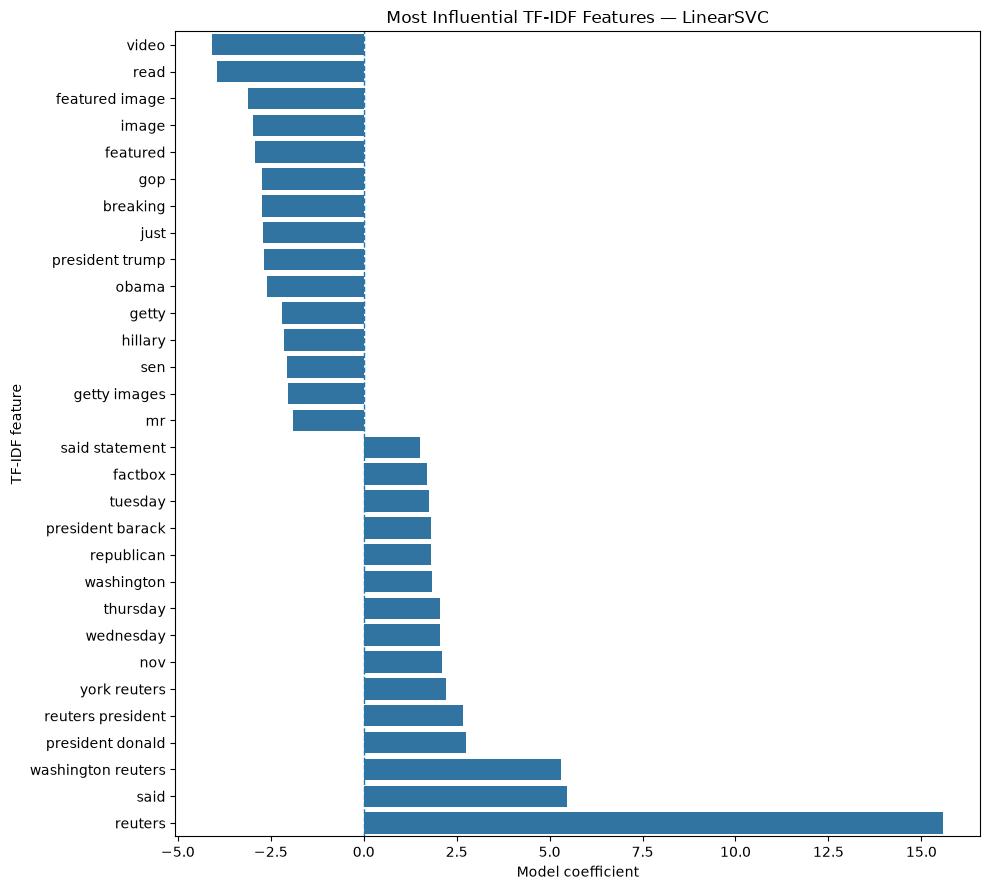

In [14]:
if coefficient_df is not None:
    top_positive = (
        coefficient_df
        .nlargest(15, "coefficient")
        .sort_values("coefficient")
    )

    top_negative = (
        coefficient_df
        .nsmallest(15, "coefficient")
        .sort_values("coefficient")
    )

    interpretation_df = pd.concat([
        top_negative,
        top_positive,
    ])

    plt.figure(figsize=(10, 9))

    sns.barplot(
        data=interpretation_df,
        x="coefficient",
        y="feature",
        orient="h",
    )

    plt.axvline(
        0,
        linestyle="--",
        linewidth=1,
    )

    plt.title(
        f"Most Influential TF-IDF Features — {type(classifier).__name__}"
    )

    plt.xlabel("Model coefficient")
    plt.ylabel("TF-IDF feature")
    plt.tight_layout()

    feature_importance_figure = (
        FIGURES_DIR / "model_interpretation_coefficients.png"
    )

    plt.savefig(
        feature_importance_figure,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
else:
    print(
        "Coefficient visualisation is not available "
        "for the selected classifier."
    )

## Save Model Interpretation

The strongest positive and negative features are saved as a report.

This provides a reproducible record of the learned vocabulary used during interpretation.

In [15]:
if coefficient_df is not None:
    feature_interpretation_path = (
        REPORTS_DIR / "model_feature_coefficients.csv"
    )

    coefficient_df.sort_values(
        "coefficient",
        ascending=False,
    ).to_csv(
        feature_interpretation_path,
        index=False,
    )

    print(
        f"Saved: {feature_interpretation_path}"
    )
else:
    print(
        "No coefficient report was created because "
        "the selected classifier does not expose coefficients."
    )

Saved: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\model_feature_coefficients.csv


## Recreate the Validation Split

Notebook 3 used a fixed random seed and stratified 80/20 split.

The same procedure is repeated here so that the saved model can be evaluated on the same validation examples without depending on Notebook 3's in-memory variables.

In [16]:
from sklearn.model_selection import train_test_split

X = modeling_df["model_text"].astype(str)
y = modeling_df["label"].astype(int)

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training documents:", len(X_train))
print("Validation documents:", len(X_valid))

Training documents: 31280
Validation documents: 7820


## Reproduce Validation Predictions

The reloaded model is used to predict the same validation subset that was used during the final evaluation in Notebook 3.

The purpose is to confirm that the persisted model reproduces the original validation behaviour.

In [17]:
validation_predictions = final_model.predict(
    X_valid
)

print("Validation predictions generated.")
print(f"Number of predictions: {len(validation_predictions)}")

Validation predictions generated.
Number of predictions: 7820


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

validation_accuracy = accuracy_score(
    y_valid,
    validation_predictions,
)

validation_precision = precision_score(
    y_valid,
    validation_predictions,
    zero_division=0,
)

validation_recall = recall_score(
    y_valid,
    validation_predictions,
    zero_division=0,
)

validation_f1 = f1_score(
    y_valid,
    validation_predictions,
    zero_division=0,
)

print(f"Accuracy : {validation_accuracy:.4f}")
print(f"Precision: {validation_precision:.4f}")
print(f"Recall   : {validation_recall:.4f}")
print(f"F1-score : {validation_f1:.4f}")

Accuracy : 0.9964
Precision: 0.9951
Recall   : 0.9983
F1-score : 0.9967


## Compare with the Saved Evaluation Report

Notebook 3 stored the final evaluation metrics in `final_model_evaluation.csv`.

The same report is loaded here so that the persisted model can be checked against the documented validation results.

In [19]:
FINAL_EVALUATION_PATH = (
    REPORTS_DIR / "final_model_evaluation.csv"
)

if FINAL_EVALUATION_PATH.exists():
    saved_evaluation = pd.read_csv(
        FINAL_EVALUATION_PATH
    )

    display(saved_evaluation)
else:
    print(
        "Final evaluation report was not found. "
        "The model itself can still be evaluated."
    )

,Final Model,CV F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Random State
0,Linear SVM (Tuned),0.996114,0.996419,0.995062,0.998349,0.996703,0.99983,42


## Reproducibility Check

The reloaded model should reproduce the same predictions for the same validation data.

This is an important practical check because the final model will later be used outside the notebook.

In [20]:
second_validation_predictions = final_model.predict(
    X_valid
)

assert np.array_equal(
    validation_predictions,
    second_validation_predictions,
), "Predictions changed between identical runs."

print(
    "Reproducibility check passed: "
    "identical inputs produced identical predictions."
)

Reproducibility check passed: identical inputs produced identical predictions.


## Validation Prediction Review

The validation predictions are combined with the original article information.

This creates a readable prediction-review dataset containing the actual label, predicted label, and model score where available.

In [21]:
validation_review = modeling_df.loc[
    X_valid.index,
    [
        "title",
        "text",
        "subject",
        "date",
        "label",
        "label_name",
    ],
].copy()

validation_review["Predicted_Label"] = (
    validation_predictions
)

validation_review["Predicted_Label_Name"] = (
    validation_review["Predicted_Label"]
    .map({
        0: "Fake",
        1: "True",
    })
)

validation_review["Correct"] = (
    validation_review["label"]
    == validation_review["Predicted_Label"]
)

if hasattr(final_model, "predict_proba"):
    validation_review["Model_Score"] = (
        final_model.predict_proba(X_valid)[:, 1]
    )

elif hasattr(final_model, "decision_function"):
    validation_review["Model_Score"] = (
        final_model.decision_function(X_valid)
    )

validation_review.head()

,title,text,subject,date,label,label_name,Predicted_Label,Predicted_Label_Name,Correct,Model_Score
12374,Meet The LEFTIST Assistant Professor Who Made Up Bogus List Of “Fake” Conservative Websites That Went Viral,"Approximately one year ago, my business partner sent me a screen shot of a list of phony or not to be trusted websites that was going around ...",politics,"Nov 16, 2016",0,Fake,0,Fake,True,-2.134865
30646,Senior North Korean diplomat meets U.N. political affairs chief,SEOUL (Reuters) - North Korea s vice foreign minister met visiting U.N. political affairs chief Jeffrey Feltman on Wednesday in the North Korean c...,worldnews,"December 6, 2017",1,True,1,True,True,0.920500
28968,"Watch out frontrunners, over 1,500 candidates vying for White House","CHICAGO (Reuters) - Michael Petyo is a carpenter, a U.S. Navy veteran, a grandfather and Russian Orthodox church cantor who likes to boast about h...",politicsNews,"January 25, 2016",1,True,1,True,True,0.432150
25544,"More Republicans expect Clinton, rather than Trump, to win U.S. election","NEW YORK (Reuters) - More Republicans now think Democrat Hillary Clinton, rather than Donald Trump, will win the presidency, as their party’s cand...",politicsNews,"October 26, 2016",1,True,1,True,True,1.602396
21818,"Trump gains traction on healthcare bill, vote set for Thursday",WASHINGTON (Reuters) - President Donald Trump’s effort to roll back Obamacare gained momentum on Wednesday as Republican leaders scheduled a vote ...,politicsNews,"May 3, 2017",1,True,1,True,True,1.673634


## Inspect Incorrect Predictions

Incorrectly classified examples are useful for understanding the model's limitations.

The purpose of this analysis is not to manually relabel the dataset, but to identify patterns that may make classification difficult for a statistical text model.

In [22]:
misclassified = (
    validation_review[
        ~validation_review["Correct"]
    ]
    .copy()
)

print(
    f"Misclassified validation examples: "
    f"{len(misclassified)}"
)

misclassified[
    [
        "title",
        "label_name",
        "Predicted_Label_Name",
        "subject",
    ]
].head(20)

Misclassified validation examples: 28


,title,label_name,Predicted_Label_Name,subject
14369,INVASION OF AMERICA: POSSIBILITY OF A TRUMP WALL Has Illegals Racing To Across The Border In Record Numbers,Fake,True,politics
14941,BREAKING: US Appeals Court Deals Obama’s Executive Amnesty Huge Blow,Fake,True,politics
16243,Putin Declares Syria A “No Fly Zone”…While Obama Is Laser Focused On Gun Control,Fake,True,Government News
15331,FED GOV FINES ILLINOIS COMPANY $1.8 MILLION FOR EXPOSING MEXICAN WORKERS TO DANGEROUS SUBSTANCE,Fake,True,politics
25782,Commentary: Manic or evasive - these veep guys sure don’t feel like leaders,True,Fake,politicsNews
1679,Court Slams Down Trump’s Order Blocking Funding To Sanctuary Cities,Fake,True,News
15707,U.S. APOLOGIZES FOR HUMAN RIGHTS VIOLATIONS AT U.N. REVIEW TO COUNTRIES WITH WORSE HUMAN RIGHTS VIOLATIONS,Fake,True,politics
11695,BREAKING: Activist Appeals Court Rules Against Trump…Trump Comes Out Swinging…Tweets Awesome Reply,Fake,True,politics
27474,Commentary: Party leaders often disliked their nominee. It’s the public vitriol that’s new.,True,Fake,politicsNews
15850,BREAKING: IRAN THROWS DOWN ULTIMATUM: …Your Move Barry,Fake,True,politics


## Most Uncertain Validation Predictions

For a binary classifier, predictions close to the decision boundary can be more difficult for the model.

The exact interpretation of the score depends on the classifier:

- Logistic Regression probabilities are between 0 and 1.
- Linear SVM decision scores represent distance from the separating boundary.

The values are therefore used mainly for relative confidence analysis.

In [23]:
if "Model_Score" in validation_review.columns:

    if hasattr(final_model, "predict_proba"):
        validation_review["Uncertainty"] = (
            np.abs(
                validation_review["Model_Score"] - 0.5
            )
        )
    else:
        validation_review["Uncertainty"] = (
            np.abs(
                validation_review["Model_Score"]
            )
        )

    uncertain_examples = (
        validation_review
        .sort_values("Uncertainty")
        .head(20)
    )

    uncertain_examples[
        [
            "title",
            "label_name",
            "Predicted_Label_Name",
            "Model_Score",
            "Correct",
        ]
    ]
else:
    print(
        "The selected classifier does not expose "
        "a continuous prediction score."
    )

## Prediction Helper

The following function provides a simple interface for predicting the class of a new article.

The function accepts a title and article body, combines them using the same structure used during model development, and sends the resulting text directly through the saved pipeline.

No manual TF-IDF transformation is performed here because the saved pipeline already contains the fitted transformation.

In [24]:
def predict_news_article(
    title: str,
    text: str,
) -> dict:
    """
    Predict the dataset-defined class for a single news article.
    """

    if not isinstance(title, str):
        raise TypeError("title must be a string.")

    if not isinstance(text, str):
        raise TypeError("text must be a string.")

    title = title.strip()
    text = text.strip()

    if not title and not text:
        raise ValueError(
            "At least a title or article body is required."
        )

    combined_text = (
        f"{title} {text}"
    ).strip()

    prediction = int(
        final_model.predict(
            [combined_text]
        )[0]
    )

    label_name = {
        0: "Fake",
        1: "True",
    }[prediction]

    result = {
        "prediction": prediction,
        "label": label_name,
    }

    if hasattr(final_model, "predict_proba"):
        probability = float(
            final_model.predict_proba(
                [combined_text]
            )[0, 1]
        )

        result["true_probability"] = probability
        result["fake_probability"] = 1 - probability

    elif hasattr(final_model, "decision_function"):
        decision_score = float(
            final_model.decision_function(
                [combined_text]
            )[0]
        )

        result["decision_score"] = decision_score

    return result

## Example Prediction

The following example demonstrates how a new article can be passed to the trained pipeline.

This is only a demonstration of model inference. The output represents the class predicted from patterns learned from the project dataset.

In [25]:
example_title = (
    "Example news article about a recent political development"
)

example_text = (
    "This is a demonstration article used to verify "
    "that the saved NLP pipeline can accept new text "
    "and return a prediction."
)

example_result = predict_news_article(
    title=example_title,
    text=example_text,
)

example_result

{'prediction': 0, 'label': 'Fake', 'decision_score': -0.26212754086915585}

## Batch Prediction

The same pipeline can also process multiple articles.

A small helper function is provided so that future predictions can be generated from a DataFrame containing `title` and `text` columns.

In [26]:
def predict_news_dataframe(
    data: pd.DataFrame,
) -> pd.DataFrame:
    """
    Generate predictions for a DataFrame containing
    title and text columns.
    """

    required_columns = [
        "title",
        "text",
    ]

    missing = [
        column
        for column in required_columns
        if column not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    prediction_input = (
        data["title"].fillna("").astype(str)
        + " "
        + data["text"].fillna("").astype(str)
    ).str.strip()

    predictions = final_model.predict(
        prediction_input
    )

    results = data.copy()

    results["Predicted_Label"] = predictions

    results["Predicted_Label_Name"] = (
        results["Predicted_Label"]
        .map({
            0: "Fake",
            1: "True",
        })
    )

    return results

## Demonstrate Batch Prediction

A small sample from the processed dataset is used only to verify that the batch prediction helper works correctly.

This does not retrain the model.

In [27]:
sample_articles = modeling_df[
    [
        "title",
        "text",
        "label_name",
    ]
].head(10).copy()

batch_predictions = predict_news_dataframe(
    sample_articles[
        [
            "title",
            "text",
        ]
    ]
)

batch_predictions

,title,text,Predicted_Label,Predicted_Label_Name
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,"Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters an...",0,Fake
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,"House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumption, like many of us, that the Christophe...",0,Fake
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,"On Friday, it was revealed that former Milwaukee Sheriff David Clarke, who was being considered for Homeland Security Secretary in Donald Trump s ...",0,Fake
3,Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),"On Christmas day, Donald Trump announced that he would be back to work the following day, but he is golfing for the fourth day in a row. The for...",0,Fake
4,Pope Francis Just Called Out Donald Trump During His Christmas Speech,Pope Francis used his annual Christmas Day message to rebuke Donald Trump without even mentioning his name. The Pope delivered his message just da...,0,Fake
5,Racist Alabama Cops Brutalize Black Boy While He Is In Handcuffs (GRAPHIC IMAGES),"The number of cases of cops brutalizing and killing people of color seems to see no end. Now, we have another case that needs to be shared far and...",0,Fake
6,"Fresh Off The Golf Course, Trump Lashes Out At FBI Deputy Director And James Comey","Donald Trump spent a good portion of his day at his golf club, marking the 84th day he s done so since taking the oath of office. It must have bee...",0,Fake
7,"Trump Said Some INSANELY Racist Stuff Inside The Oval Office, And Witnesses Back It Up","In the wake of yet another court decision that derailed Donald Trump s plan to bar Muslims from entering the United States, the New York Times pub...",0,Fake
8,"Former CIA Director Slams Trump Over UN Bullying, Openly Suggests He’s Acting Like A Dictator (TWEET)","Many people have raised the alarm regarding the fact that Donald Trump is dangerously close to becoming an autocrat. The thing is, democracies bec...",0,Fake
9,WATCH: Brand-New Pro-Trump Ad Features So Much A** Kissing It Will Make You Sick,"Just when you might have thought we d get a break from watching people kiss Donald Trump s ass and stroke his ego ad nauseam, a pro-Trump group cr...",0,Fake


## Save Prediction Demonstration

The demonstration predictions are saved as a small report that can be inspected later.

The original dataset label is retained only for comparison because this sample comes from the labelled dataset.

In [28]:
sample_prediction_path = (
    REPORTS_DIR / "sample_predictions.csv"
)

batch_predictions.to_csv(
    sample_prediction_path,
    index=False,
)

print(
    f"Saved: {sample_prediction_path}"
)

Saved: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\sample_predictions.csv


## Model Behaviour by Subject

The model is trained using article text rather than subject metadata.

However, subject-level validation behaviour can still be inspected after prediction to understand whether performance varies across the dataset's subject categories.

This is an analysis of dataset behaviour, not a feature used by the primary classifier.

In [29]:
subject_performance = (
    validation_review
    .groupby("subject")
    .agg(
        Articles=("Correct", "size"),
        Accuracy=("Correct", "mean"),
    )
    .reset_index()
    .sort_values(
        "Articles",
        ascending=False,
    )
)

subject_performance

,subject,Articles,Accuracy
5,politicsNews,2172,0.996777
6,worldnews,2067,1.000000
1,News,1768,0.998869
4,politics,1385,0.989170
2,US_News,171,0.994152
3,left-news,148,0.993243
0,Government News,109,0.981651


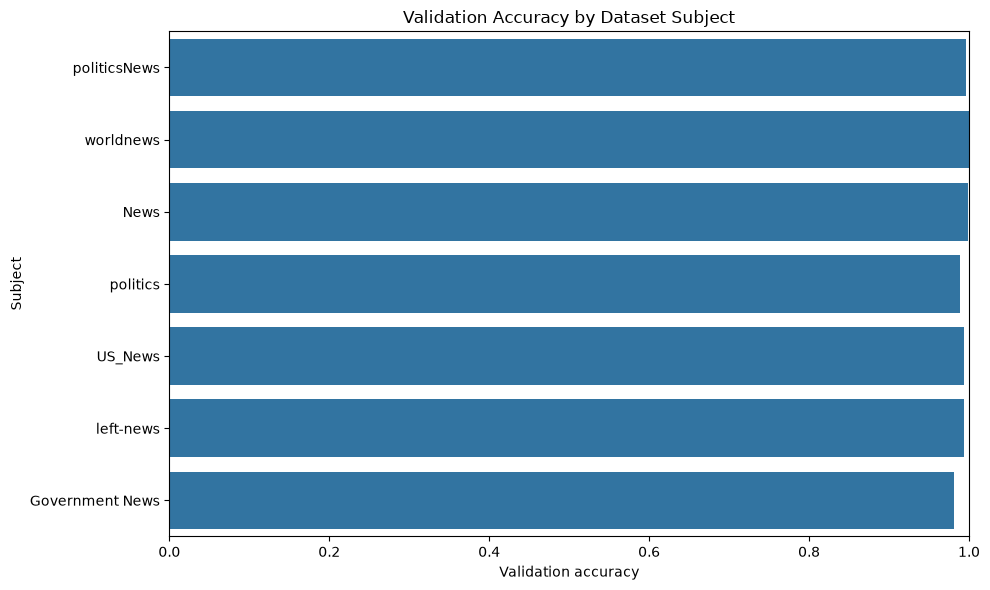

In [30]:
subject_performance_figure = (
    subject_performance
    .sort_values("Articles", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=subject_performance_figure,
    x="Accuracy",
    y="subject",
)

plt.xlim(0, 1)
plt.xlabel("Validation accuracy")
plt.ylabel("Subject")
plt.title("Validation Accuracy by Dataset Subject")
plt.tight_layout()

subject_figure_path = (
    FIGURES_DIR / "validation_accuracy_by_subject.png"
)

plt.savefig(
    subject_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

## Limitations and Responsible Interpretation

Several limitations should be kept in mind when interpreting this project.

### Dataset-dependent labels

The model learns the labels supplied by the dataset. It does not independently verify the factual accuracy of an article.

### Dataset-specific language patterns

The classifier may learn writing style, recurring phrases, source-specific vocabulary, or other patterns that work well within this dataset but may not generalise to unseen news sources.

### Metadata is not the primary predictive input

Subject and date were retained for analysis but were not used as primary classifier features. This reduces reliance on obvious metadata shortcuts.

### Distribution shift

Real-world news language changes over time. A model trained on historical articles may perform differently on newer articles.

### Human verification

A prediction from this model should not be treated as definitive evidence that a real-world article is fake or true. For practical fact-checking, independent source verification and human review remain important.

## Save Final Model Summary

A compact summary of the final model, feature representation, validation behaviour, and project limitations is saved for future reference.

In [31]:
model_summary = pd.DataFrame([
    {
        "Model": type(classifier).__name__,
        "Pipeline": "TF-IDF + Classifier",
        "Feature_Count": len(feature_names),
        "Ngram_Range": str(tfidf_model.ngram_range),
        "Validation_Accuracy": validation_accuracy,
        "Validation_Precision": validation_precision,
        "Validation_Recall": validation_recall,
        "Validation_F1": validation_f1,
        "Random_State": RANDOM_STATE,
    }
])

model_summary_path = (
    REPORTS_DIR / "final_model_summary.csv"
)

model_summary.to_csv(
    model_summary_path,
    index=False,
)

model_summary

,Model,Pipeline,Feature_Count,Ngram_Range,Validation_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Random_State
0,LinearSVC,TF-IDF + Classifier,100000,"(1, 2)",0.996419,0.995062,0.998349,0.996703,42


## Final Model Integrity Checks

Before closing the modelling notebooks, a final set of checks is performed.

The checks confirm that:

- the processed dataset exists
- the saved model exists
- the pipeline contains TF-IDF
- the pipeline contains a classifier
- predictions can be generated
- repeated predictions are identical
- the saved model can be used for new text

In [32]:
assert PROCESSED_DATA_PATH.exists(), (
    "Processed modelling dataset is missing."
)

assert FINAL_MODEL_PATH.exists(), (
    "Final saved model is missing."
)

assert "tfidf" in final_model.named_steps, (
    "TF-IDF step is missing from the final pipeline."
)

assert len(classifier_name) > 0, (
    "Classifier step is missing."
)

assert len(validation_predictions) == len(y_valid), (
    "Validation prediction count does not match labels."
)

assert np.array_equal(
    validation_predictions,
    second_validation_predictions,
), (
    "Repeated predictions are not identical."
)

new_text_test = predict_news_article(
    title="Test article title",
    text="Test article body for pipeline validation.",
)

assert "label" in new_text_test, (
    "New-text prediction did not return a label."
)

print("All final integrity checks passed.")

All final integrity checks passed.


## Project-Level Interpretation

The project now demonstrates a complete classical NLP classification workflow.

The important technical components are connected across the notebooks:

- data quality controls from Notebook 1
- text and vocabulary analysis from Notebook 2
- leakage-safe TF-IDF modelling from Notebook 3
- model comparison and cross-validation from Notebook 3
- hyperparameter tuning from Notebook 3
- validation-based evaluation from Notebook 3
- feature-level model interpretation from this notebook
- reusable prediction functions from this notebook
- model persistence and reproducibility checks from this notebook

The final model is therefore not just a single classifier trained on raw text. It is a reproducible NLP pipeline that combines text representation, machine learning, evaluation, interpretation, and inference.

In [33]:
print("=" * 70)
print("NOTEBOOK 4 — MODEL INTERPRETATION AND PREDICTION COMPLETE")
print("=" * 70)

print(f"\nFinal classifier: {type(classifier).__name__}")
print(f"TF-IDF features: {len(feature_names)}")

print("\nValidation Performance")
print("-" * 30)
print(f"Accuracy : {validation_accuracy:.4f}")
print(f"Precision: {validation_precision:.4f}")
print(f"Recall   : {validation_recall:.4f}")
print(f"F1-score : {validation_f1:.4f}")

print("\nSaved model:")
print(FINAL_MODEL_PATH)

print("\nSaved reports:")
print(model_summary_path)
print(sample_prediction_path)

if coefficient_df is not None:
    print(feature_interpretation_path)

print("\nModel reproducibility check: PASSED")
print("New-text prediction check: PASSED")

print("\nAll four project notebooks are now complete.")

NOTEBOOK 4 — MODEL INTERPRETATION AND PREDICTION COMPLETE

Final classifier: LinearSVC
TF-IDF features: 100000

Validation Performance
------------------------------
Accuracy : 0.9964
Precision: 0.9951
Recall   : 0.9983
F1-score : 0.9967

Saved model:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\models\fake_news_final_model.joblib

Saved reports:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\final_model_summary.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\sample_predictions.csv
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\model_feature_coefficients.csv

Model reproducibility check: PASSED
New-text prediction check: PASSED

All four project notebooks are now complete.
